# 08B.0 — Outcome resolution and freeze

**Objective O1 — semantic credibility.** What exactly do the candidate NFL football outcomes mean, which opportunity denominators are justified, and which definitions may the rest of Milestone 08B use?

This notebook resolves the provisional status left by 08A.2 **without manufacturing certainty**:

- it audits the lineage of every field used by an outcome or a denominator;
- it classifies each definition `CONFIRMED` · `DERIVED_VERIFIED` · `PROVISIONAL` · `BLOCKED` from recorded source evidence and the 08A.2 audit;
- it records **your** decision (`FREEZE` · `PROVISIONAL` · `STOP`) in an immutable registry `football_outcome_registry_<version>.json`.

A decision never raises a source class. Nothing here reads a Combine value, and no NFL outcome is related to anything outside the NFL player-play table.

**Prerequisites (same `RUN_MODE`).** 08A and 08A.2 executed. No PyTorch. Run time: seconds.

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full' — must match notebooks 08A / 08A.2
SEED = 20261011
FORCE_REBUILD = False         # interface parity: every table of this notebook is recomputed on each run (seconds)
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
EXPERIMENT_VERSION = '08B0.1'
REGISTRY_VERSION = 'v1'       # a changed decision or definition needs a NEW version ('v2'); the old file stays
SHOW_TABLES = True

## Source evidence (fill only from an authoritative source)

The repository holds no vendor data dictionary, so every definition is **inferred** until you record evidence here. Quote the competition data dictionary (or another authoritative source) — never paraphrase from memory, never fill from a column name.

- `DEFINITION_EVIDENCE` — outcome level, as in 08A.2: `{osm.FO01: {'status': 'confirmed_source', 'source': '<document, section>', 'definition': '<quoted text>'}}`.
- `FIELD_EVIDENCE` — field level: `{'separation_at_pass_forward': {'source': '...', 'definition': '...'}, 'route_ran': {...}}`. A definition is `CONFIRMED` only when the outcome **and every field it needs** are confirmed.

Leave both empty when no source is available: the provisional status stays visible and the exploratory branch remains possible through an explicit acknowledgement.

In [2]:
DEFINITION_EVIDENCE = {}
FIELD_EVIDENCE = {}

In [3]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import football_figures as ff
from nflbdb.research.advanced_movement import football_registry as fr
from nflbdb.research.advanced_movement import football_validation as fv
from nflbdb.research.advanced_movement import opportunity_validation as ov
from nflbdb.research.advanced_movement import outcome_semantics as osm
from nflbdb.research.advanced_movement.artifacts import FootballStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = FootballStore(cfg, controls)
S8 = store.scouting                                   # 08A / 08A.2 outputs — READ ONLY
amc.seed_everything(controls.seed)
NB = {'08A': '08a_football_outcome_feasibility.ipynb', '08A2': '08a2_outcome_semantics_and_opportunity_validation.ipynb',
      '08B0': '08b0_outcome_resolution_and_freeze.ipynb'}

# ---- executed 08A.2 tables (nothing is recomputed from the warehouse here)
candidates, checks = S8.require(osm.CANDIDATES, NB['08A2']), S8.require(osm.CHECKS, NB['08A2'])
zero_missing, structure, credit = (S8.require(c, NB['08A2']) for c in (osm.ZERO_MISSING, osm.STRUCTURE, osm.CREDIT))
sep_dist, context_fields = S8.require(osm.SEP_DIST, NB['08A2']), S8.require(osm.CONTEXT_T, NB['08A2'])
denoms, reliability, dependence, ranking = (S8.require(c, NB['08A2']) for c in (ov.DENOMS, ov.RELIABILITY, ov.DEPENDENCE, ov.RANKING))
athletes, links, funnel = (S8.require(c, NB['08A2']) for c in (ov.ATHLETES, ov.LINKS, ov.FUNNEL))
p08 = S8.read_json(ov.PROPOSAL_FILE, NB['08A2'])

# ---- the exact validation configuration and declarations 08A.2 ran with
params = p08['provenance']['params']
vc = ov.ValidationConfig(**{k: (tuple(v) if isinstance(v, list) else v) for k, v in params['validation'].items() if k != 'validation_version'})
assert params['denominators'] == ov.denominators_hash(), 'the denominator declarations changed since 08A.2 was executed: rerun 08A.2'
assert params['semantics'] == osm.definition_hash(), 'the semantic declarations changed since 08A.2 was executed: rerun 08A.2'
PROV = {'notebook': NB['08B0'], 'experiment_version': EXPERIMENT_VERSION, 'validation_08a2_finished_at': p08.get('finished_at'),
        'denominators': ov.denominators_hash(), 'semantics': osm.definition_hash(), 'run_mode': controls.run_mode, 'seed': controls.seed,
        'definition_evidence': DEFINITION_EVIDENCE, 'field_evidence': FIELD_EVIDENCE}
save = lambda df, contract: store.write(df, contract, '08B0', PROV) if controls.save_tables else df

label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · 08A.2 finished {p08.get("finished_at")} · semantics `{osm.definition_hash()}` · '
                 f'denominators `{ov.denominators_hash()}` · {athletes["nfl_id"].n_unique()} athletes with an outcome value'))
display(store.describe())

**Run mode: `full`** (FULL) · 08A.2 finished 2026-10-13T18:40:12Z · semantics `84750edb2d16171b` · denominators `a03e896f0f00d63d` · 310 athletes with an outcome value

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


## 1 · Synthetic checks of the registry logic

Planted, known answers: null versus zero, source classes that are never upgraded, redundancy of identical definitions, the three decision states, immutability and hash verification. A failing check stops the notebook.

In [4]:
validation = fv.run_all(fv.CHECKS_SEMANTICS)
with pl.Config(fmt_str_lengths=200, tbl_rows=-1):
    display(validation)
fv.assert_all_passed(validation)

21:46:07 | INFO    | nflbdb.research.advanced_movement.football_registry | [football_registry] football_outcome_registry_v1.json written: FREEZE ['FO01.S0']
21:46:07 | INFO    | nflbdb.research.advanced_movement.football_registry | [football_registry] football_outcome_registry_v2.json written: PROVISIONAL ['FO01.S0']
21:46:07 | INFO    | nflbdb.research.advanced_movement.football_registry | [football_registry] football_outcome_registry_v3.json written: STOP []


check,status,detail
str,str,str
"""missing_zero_units_and_attribution""","""PASS""","""null ≠ zero; units, timing and attribution declared; a field is confirmed only by a source and a quoted definition"""
"""source_classes_never_upgraded""","""PASS""","""source classes come from recorded evidence and the audit; structural denominators cap at PROVISIONAL"""
"""equivalence_and_redundancy""","""PASS""","""S1 identical to S0 → redundant (S0 retained); a different S1 stays a distinct definition"""
"""decision_states_and_immutable_registry""","""PASS""","""FREEZE / PROVISIONAL / STOP semantics, acknowledgement, immutability, versioning and hash verification"""
"""denominators_duplicates_and_position_eligibility""","""PASS""","""context rows equal the 08A.2 denominators; positions restricted; missing labels are not inferred"""


## 2 · Source lineage

One row per field used by an outcome or an opportunity denominator: declared meaning, units, timing, player attribution, required observations, missing and zero rules, allowed context, limitations — plus what 08A.2 **measured** (null and zero shares) and the evidence recorded above.

The second table is a plain text search of the repository documentation for the field names. A hit is something to **read**; it confirms nothing by itself.

In [5]:
SEMANTIC = osm.semantic_status(checks, DEFINITION_EVIDENCE)
lineage = save(fr.lineage_table(zero_missing, FIELD_EVIDENCE), fr.LINEAGE_T)

root = cfg.paths.project_root
DOC_FILES = sorted({*root.glob('docs/**/*.md'), *root.glob('reports/0*.md'), *root.glob('*.md'), *root.glob('data/**/*.md'), *root.glob('data/**/*.txt'),
                    *root.glob('data/**/*dictionary*'), *root.glob('data/**/*README*')})
mentions = save(fr.repository_evidence(DOC_FILES, [f.field for f in fr.LINEAGE if ' ' not in f.field], cfg.paths.rel), fr.REPO_EVIDENCE)

if SHOW_TABLES:
    with pl.Config(fmt_str_lengths=160, tbl_rows=-1, tbl_width_chars=260):
        display(lineage.select('field', 'outcome', 'role', 'units', 'semantic_confidence', 'share_null', 'share_zero', 'source_evidence'))
        display(lineage.select('field', 'semantic_meaning', 'timing', 'missing_value_rule', 'zero_value_rule', 'limitations'))
        display(Markdown(f'**Repository mentions** ({len(DOC_FILES)} documentation files searched): {mentions.height} line(s)'))
        display(mentions.head(40))
print('semantic status of the outcomes:', {k: v['status'] for k, v in SEMANTIC.items()})

21:46:08 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B0] football_outcome_source_lineage: 12 rows → warehouse/gold/advanced_movement/football_v1/football_outcome_source_lineage.parquet
21:46:09 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B0] football_outcome_repository_mentions: 62 rows → warehouse/gold/advanced_movement/football_v1/football_outcome_repository_mentions.parquet


field,outcome,role,units,semantic_confidence,share_null,share_zero,source_evidence
str,str,str,str,str,f64,f64,str
"""separation_at_pass_forward""","""FO01.*""","""outcome_value""","""yd (inferred from the value range)""","""inferred""",0.845412,0.0,"""none recorded: no vendor data dictionary found in the repository"""
"""route_ran""","""FO01.S1 · FO01.S2""","""context""","""label""","""inferred""",0.823387,0.0,"""none recorded: no vendor data dictionary found in the repository"""
"""lined_up_position""","""FO01.S2""","""context""","""label""","""inferred""",null,null,"""none recorded: no vendor data dictionary found in the repository"""
"""cushion""","""FO03 (context, blocked as an outcome)""","""context""","""yd (inferred)""","""inferred""",0.654875,0.0,"""none recorded: no vendor data dictionary found in the repository"""
"""target""","""FO01.S0T · FO01.S0N""","""opportunity_filter""","""flag""","""inferred""",0.009217,0.958813,"""none recorded: no vendor data dictionary found in the repository"""
"""tackle""","""FO12.*""","""outcome_value""","""count per player-play (0 / 1)""","""inferred""",0.961127,0.015076,"""none recorded: no vendor data dictionary found in the repository"""
"""assist""","""FO12.T2""","""outcome_value""","""count per player-play""","""inferred""",0.961127,0.02381,"""none recorded: no vendor data dictionary found in the repository"""
"""sack""","""FO13.*""","""outcome_value""","""sack credit per player-play (0 / 0.5 / 1)""","""inferred""",0.717687,0.280537,"""none recorded: no vendor data dictionary found in the repository"""
"""coverage_assignment""","""FO13.K1""","""opportunity_filter""","""label""","""inferred""",0.716687,0.0,"""none recorded: no vendor data dictionary found in the repository"""


field,semantic_meaning,timing,missing_value_rule,zero_value_rule,limitations
str,str,str,str,str,str
"""separation_at_pass_forward""","""distance from the player to the nearest defender at the frame tagged pass_forward (INFERRED)""","""one value per player-play at the pass release; the release frame is not delivered with the value""","""null = not recorded; never read as 0""","""0 would be a physical distance of zero; no structural zero expected""","""nearest defender cannot be recomputed (only project athletes are tracked); interaction outcome"""
"""route_ran""","""route label of the player on the play (INFERRED)""","""labelled after the play (an assignment label)""","""null / empty = no route label; a missing route is never inferred""","""not applicable""","""route mix is partly a property of the player"""
"""lined_up_position""","""alignment of the player on the play (INFERRED)""","""pre-snap""","""null = not recorded""","""not applicable""","""the team chooses the alignment"""
"""cushion""","""pre-snap distance to the defender across (INFERRED)""","""pre-snap""","""null = not recorded""","""unknown""","""a defensive choice: a contextual variable, not an outcome of the receiver"""
"""target""","""the pass was thrown to the player (INFERRED)""","""known after the throw""","""null = unknown; never read as 'not targeted'""","""false is a recorded statement""","""outcome-dependent: the quarterback throws to the open receiver"""
"""tackle""","""credited solo tackle of the player on the play (INFERRED)""","""credited statistic of the play (not a tracking event)""","""null = no tackle statistic recorded; 'no credit' is an INFERENCE of the structural denominators""","""a recorded 0 exists on rows created by another credited statistic (assist)""","""no field records a tackle opportunity; credit depends on role, scheme, run direction, playing time"""
"""assist""","""credited assisted tackle of the player on the play (INFERRED)""","""credited statistic of the play""","""null = no statistic recorded""","""recorded 0 on credited-tackle rows""","""solo versus assisted is a scorer's judgement"""
"""sack""","""sack credit of the player on the play (0.5 = shared) (INFERRED)""","""credited statistic of the play""","""null = no sack statistic recorded (e.g. a run play); never read as 0 in K0""","""0 is recorded explicitly on a subset of plays""","""rare event; rush assignment, protection, quarterback and game script are unobserved"""
"""coverage_assignment""","""assignment label of a defender; NO_ASSIGNMENT is a vendor token (INFERRED)""","""labelled after the play""","""null = not recorded""","""not applicable""","""NO_ASSIGNMENT is NOT verified pass rushing"""


**Repository mentions** (18 documentation files searched): 62 line(s)

field,file,line,text
str,str,i64,str
"""target""","""docs/ACTIVE_TASK.md""",29,"""- The 08A.2 registry `football_outcome_targets_<version>.json` is superseded by the 08B.0 registry."""
"""target""","""docs/PHASE_04_PLAN.md""",22,"""- **A3 [executed], tier discrimination.** `tier_not_A` has AUC 0.50 for every target in the Combine data. The continuous metrics do discriminate: `speed_vendor_…"
"""target""","""docs/RESEARCH_DECISIONS.md""",9,"""| D-05-1 | 05B | NFL targets `nfl_movement_targets_v1` (hash `8ff9fc191616711a`): primary `O2.accel_sust05_mean` (cell_residual), secondary `O3.band_acc_v0_2_me…"
"""target""","""docs/RESEARCH_DECISIONS.md""",11,"""| D-07-1 | 07 | C1–C4 context-adjusted targets and the 07B hypothesis registry are exploratory; scorecard (07D) is descriptive, no NFL input | `…/context_transf…"
"""target""","""docs/RESEARCH_DECISIONS.md""",14,"""| D-08A2-2 | 08A.2 | Football-outcome target freeze in 08A.2: no decision was recorded (executed 2026-10-13, gate PENDING; rule-based proposal PROVISIONAL · `FO…"
"""target""","""docs/SESSION_STATE.md""",7,"""- **08A.2 result (verified in `reports/tables/advanced_movement/scouting_v1/football_outcome_screen.csv`):** `FO01.S0` separation provisional (reliability 0.74,…"
"""separation_at_pass_forward""","""docs/SESSION_STATE.md""",25,"""- **Open scientific points:** vendor definition of `separation_at_pass_forward` (no data dictionary in the repository); `player_get_off`; handedness of the Comb…"
"""target""","""docs/SESSION_STATE.md""",32,"""- **Current milestone: 08 (football-relevant transfer + scouting decision framework), phases A–E, stop after each.** 08A EXECUTED by the user (full; gate PASS, …"
"""tackle""","""docs/SESSION_STATE.md""",32,"""- **Current milestone: 08 (football-relevant transfer + scouting decision framework), phases A–E, stop after each.** 08A EXECUTED by the user (full; gate PASS, …"


semantic status of the outcomes: {'FO01.separation_at_pass_forward': 'plausible_inferred', 'FO12.tackle': 'plausible_inferred', 'FO13.sack': 'plausible_inferred'}


## 3 · FO01 — separation at pass forward

What the audit can and cannot establish:

- **Physical distance, units, range** — non-negative values with a median inside the range declared for yards (blocking checks of 08A.2).
- **Distance to the nearest defender** — cannot be recomputed: only the project athletes are tracked. This stays an inference.
- **Timing** — the release frame is not delivered with the value.
- **Targeted versus non-targeted, route participation** — measured below (share recorded by target status and by route label).
- **S0 versus S1** — compared operationally: if every recorded separation carries a route label, S1 is the same quantity and is classified *redundant*.
- **S2** — kept as a context sensitivity unless its own reliability supports promotion.

Recorded separation is an interaction outcome; it is never called receiver ability.

In [6]:
equivalences = save(fr.equivalence_table(athletes, (('FO01.S0', 'FO01.S1'),)), fr.EQUIVALENCE)
if SHOW_TABLES:
    with pl.Config(fmt_str_lengths=180, tbl_rows=-1, tbl_width_chars=260):
        display(checks.filter(pl.col('outcome_id') == osm.FO01).select('check', 'observed', 'passed', 'blocking', 'meaning'))
        display(structure.filter((pl.col('outcome_id') == osm.FO01) & pl.col('group_field').is_in(['target', 'has:route_ran', 'position_group', 'season'])))
        display(sep_dist)
        display(equivalences)
        display(ranking.filter(pl.col('outcome_id') == osm.FO01))
display(Markdown('**S0 versus S1:** ' + equivalences['reading'][0]))

21:46:09 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B0] football_outcome_definition_equivalence: 1 rows → warehouse/gold/advanced_movement/football_v1/football_outcome_definition_equivalence.parquet


check,observed,passed,blocking,meaning
str,str,bool,bool,str
"""field_present""","""separation_at_pass_forward: present""",true,true,"""the value field exists in silver.player_play"""
"""one_row_per_player_play""","""0 conflicting duplicates (0 duplicated rows)""",true,true,"""duplicated vendor rows carry the same values (the first is kept)"""
"""recorded_share""","""37,398 of 44,960 eligible player-plays (83.2 %)""",null,false,"""share of eligible player-plays of the declared positions with a recorded value"""
"""recorded_zero""","""0 recorded zeros · 37,398 positive""",null,false,"""a recorded zero is a statement by the vendor; a null is not"""
"""non_negative""","""min 0.128""",true,true,"""a distance cannot be negative"""
"""unit_plausible_yards""","""median 2.67""",true,true,"""a median nearest-defender distance outside 0.5–10 yd contradicts 'yards' (range declared before reading)"""
"""recorded_for_non_targeted""","""targeted 100.0 % · not targeted 84.8 %""",true,false,"""if the value existed for targeted receivers only, the quarterback's choice would select the plays"""
"""route_label_coverage""","""100.0 % of recorded values carry a route label · 87.5 % of labelled routes carry a value""",null,false,"""the route label documents that the player was in a route (denominator S1)"""
"""nearest_defender_recomputable""","""median 2 tracked athletes per play (max 11)""",false,false,"""with only the project athletes tracked, 'distance to the nearest defender' cannot be recomputed from tracking"""


outcome_id,group_field,group_value,n_rows,n_obs,obs_share,n_zero,n_positive,mean_value
str,str,str,i64,i64,f64,i64,i64,f64
"""FO01.separation_at_pass_forward""","""target""","""false""",34996,29665,0.847668,0,29665,2.992691
"""FO01.separation_at_pass_forward""","""target""","""true""",7733,7733,1.0,0,7733,3.768805
"""FO01.separation_at_pass_forward""","""target""","""‹null›""",2231,0,0.0,0,0,null
"""FO01.separation_at_pass_forward""","""has:route_ran""","""recorded""",42729,37398,0.875237,0,37398,3.153172
"""FO01.separation_at_pass_forward""","""has:route_ran""","""‹null›""",2231,0,0.0,0,0,null
"""FO01.separation_at_pass_forward""","""position_group""","""WR""",36836,30852,0.83755,0,30852,3.109954
"""FO01.separation_at_pass_forward""","""position_group""","""TE""",8124,6546,0.805761,0,6546,3.356865
"""FO01.separation_at_pass_forward""","""season""","""2025""",20268,16867,0.832199,0,16867,3.130311
"""FO01.separation_at_pass_forward""","""season""","""2024""",15896,13142,0.826749,0,13142,3.164621


position_group,target,n_obs,n_athletes,mean,sd,p05,p25,median,p75,p95,max,share_extreme,share_below_half_yard
str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""ALL""","""ALL""",37398,116,3.153172,2.160172,0.737564,1.416757,2.669522,4.360046,7.2069,22.794132,0.000562,0.006471
"""ALL""","""not_targeted""",29665,116,2.992691,2.063665,0.716938,1.342125,2.520674,4.121468,6.843537,22.794132,0.000573,0.007315
"""ALL""","""targeted""",7733,107,3.768805,2.398533,0.881419,1.77192,3.365368,5.255873,8.154073,17.716084,0.000517,0.003233
"""TE""","""ALL""",6546,33,3.356865,2.355125,0.716938,1.486607,2.854339,4.564263,7.860102,22.794132,0.001069,0.007791
"""TE""","""not_targeted""",5234,33,3.128522,2.271506,0.67897,1.348073,2.590232,4.264106,7.5282,22.794132,0.001146,0.009171
"""TE""","""targeted""",1312,28,4.2678,2.460999,0.94541,2.332381,4.025966,5.682543,8.94005,15.056281,0.000762,0.002287
"""WR""","""ALL""",30852,83,3.109954,2.114018,0.741485,1.404635,2.626737,4.31677,7.101078,17.716084,0.000454,0.006191
"""WR""","""not_targeted""",24431,83,2.96359,2.015213,0.721803,1.340597,2.50697,4.081789,6.731159,17.675819,0.00045,0.006917
"""WR""","""targeted""",6421,79,3.666846,2.372886,0.871321,1.688342,3.198031,5.117978,7.993554,17.716084,0.000467,0.003426


definition_a,definition_b,n_athletes_a,n_athletes_b,n_common,n_same_observations,max_abs_value_difference,spearman,identical,reading
str,str,i64,i64,i64,i64,f64,f64,bool,str
"""FO01.S0""","""FO01.S1""",116,116,116,116,0.0,1.0,true,"""FO01.S1 is operationally identical to FO01.S0 on the observed data: retain FO01.S0, classify FO01.S1 as redundant"""


outcome_id,definition_a,definition_b,position_group,n_common,spearman,mean_abs_pct_shift,max_abs_pct_shift
str,str,str,str,i64,f64,f64,f64
"""FO01.separation_at_pass_forward""","""FO01.S0""","""FO01.S0|median""","""ALL""",102,0.915335,8.819172,40.740741
"""FO01.separation_at_pass_forward""","""FO01.S0""","""FO01.S0|median""","""TE""",27,0.876679,10.699588,40.740741
"""FO01.separation_at_pass_forward""","""FO01.S0""","""FO01.S0|median""","""WR""",75,0.930071,8.142222,25.333333
"""FO01.separation_at_pass_forward""","""FO01.S0""","""FO01.S1""","""ALL""",102,1.0,0.0,0.0
"""FO01.separation_at_pass_forward""","""FO01.S0""","""FO01.S1""","""TE""",27,1.0,0.0,0.0
"""FO01.separation_at_pass_forward""","""FO01.S0""","""FO01.S1""","""WR""",75,1.0,0.0,0.0
"""FO01.separation_at_pass_forward""","""FO01.S0""","""FO01.S1|median""","""ALL""",102,0.915335,8.819172,40.740741
"""FO01.separation_at_pass_forward""","""FO01.S0""","""FO01.S1|median""","""TE""",27,0.876679,10.699588,40.740741
"""FO01.separation_at_pass_forward""","""FO01.S0""","""FO01.S1|median""","""WR""",75,0.930071,8.142222,25.333333


**S0 versus S1:** FO01.S1 is operationally identical to FO01.S0 on the observed data: retain FO01.S0, classify FO01.S1 as redundant

## 4 · FO12 — tackles

Four different things must not be confused: a **credited tackle**, a **credited assist**, an **eligible defensive snap**, and an actual **tackle opportunity** (which no field records).

- `FO12.T0` (credited rows only) is not a rate per opportunity: the rows exist only when a statistic was credited.
- `FO12.T1` (solo tackles per snap) was rejected by the 08A.2 screen on reliability and stays rejected unless new data justify it.
- `FO12.T2` (tackle or assist per snap) is a **participation-credit rate**. It is never called tackle success probability, and it can only be a secondary target.

In [7]:
if SHOW_TABLES:
    with pl.Config(fmt_str_lengths=180, tbl_rows=-1, tbl_width_chars=260):
        display(checks.filter(pl.col('outcome_id') == osm.FO12).select('check', 'observed', 'passed', 'blocking', 'meaning'))
        display(credit.filter(pl.col('field').is_in(['tackle', 'assist'])))
        display(denoms.filter((pl.col('outcome_id') == osm.FO12) & (pl.col('position_group') == ov.ALL)).select('denominator_id', 'legitimacy', 'formula', 'assumption', 'n_athletes_supported'))

check,observed,passed,blocking,meaning
str,str,bool,bool,str
"""field_present""","""tackle: present""",true,true,"""the value field exists in silver.player_play"""
"""one_row_per_player_play""","""0 conflicting duplicates (0 duplicated rows)""",true,true,"""duplicated vendor rows carry the same values (the first is kept)"""
"""recorded_share""","""9,243 of 114,277 eligible player-plays (8.1 %)""",null,false,"""share of eligible player-plays of the declared positions with a recorded value"""
"""recorded_zero""","""3,630 recorded zeros · 5,613 positive""",null,false,"""a recorded zero is a statement by the vendor; a null is not"""
"""values_in_declared_set""","""0 recorded values outside [0.0, 1.0]""",true,true,"""a credit takes the declared values only"""
"""play_total_at_most_one""","""2 of 11,635 plays with a total above 1 over the delivered rows""",null,false,"""a shared credit cannot exceed 1 per play (only the delivered player rows are summed)"""
"""zero_explained_by_assist""","""99.9 % of recorded zeros have assist > 0""",null,false,"""what a recorded 0 means: a row created by another credited statistic"""
"""zero_explained_by_tackle_for_loss""","""0.0 % of recorded zeros have tackle_for_loss > 0""",null,false,"""what a recorded 0 means: a row created by another credited statistic"""
"""zero_explained_by_caused_forced_fumble""","""0.6 % of recorded zeros have caused_forced_fumble > 0""",null,false,"""what a recorded 0 means: a row created by another credited statistic"""


field,total_credit,n_plays,median_rows_recorded
str,f64,i64,f64
"""assist""",0.0,7329,1.0
"""assist""",1.0,4095,1.0
"""assist""",2.0,211,2.0
"""tackle""",0.0,4260,1.0
"""tackle""",1.0,7373,1.0
"""tackle""",2.0,2,1.5


denominator_id,legitimacy,formula,assumption,n_athletes_supported
str,str,str,str,i64
"""FO12.T0""","""credited_only""","""mean of tackle over eligible player-plays with a recorded tackle value""","""the rows exist only when a tackle statistic was credited: non-successes are not observed""",114
"""FO12.T1""","""structural""","""sum of (tackle > 0) over ALL eligible player-plays of the athlete / number of those player-plays""","""a null is read as 'no tackle credited'; snaps on the field are exposure, not tackle opportunities""",171
"""FO12.T2""","""structural""","""sum of (tackle > 0 or assist > 0) over ALL eligible player-plays of the athlete / number of those player-plays""","""a null is read as 'no credit'; snaps on the field are exposure, not tackle opportunities""",171


## 5 · FO13 — sacks

- A recorded 0 and a null are different statements: K0 uses recorded rows only; K2 reads a null as *no sack* (an inference) and puts run plays in the denominator.
- No field records that the player rushed the passer. `NO_ASSIGNMENT` is a vendor token, **not** verified pass rushing (K1 is sensitivity only).
- The 08A.2 screen measured a strong association of the sack rate with its own exposure: a rate that follows playing time ranks usage.

Neither K0 nor K2 is ever called a pass-rush win rate.

In [8]:
if SHOW_TABLES:
    with pl.Config(fmt_str_lengths=180, tbl_rows=-1, tbl_width_chars=260):
        display(checks.filter(pl.col('outcome_id') == osm.FO13).select('check', 'observed', 'passed', 'blocking', 'meaning'))
        display(structure.filter((pl.col('outcome_id') == osm.FO13) & pl.col('group_field').is_in(['play_class', 'has:coverage_assignment', 'coverage_assignment'])))
        display(dependence.filter(pl.col('denominator_id').str.starts_with('FO13')))

check,observed,passed,blocking,meaning
str,str,bool,bool,str
"""field_present""","""sack: present""",true,true,"""the value field exists in silver.player_play"""
"""one_row_per_player_play""","""0 conflicting duplicates (0 duplicated rows)""",true,true,"""duplicated vendor rows carry the same values (the first is kept)"""
"""recorded_share""","""28,962 of 50,363 eligible player-plays (57.5 %)""",null,false,"""share of eligible player-plays of the declared positions with a recorded value"""
"""recorded_zero""","""28,567 recorded zeros · 395 positive""",null,false,"""a recorded zero is a statement by the vendor; a null is not"""
"""values_in_declared_set""","""0 recorded values outside [0.0, 0.5, 1.0]""",true,true,"""a credit takes the declared values only"""
"""play_total_at_most_one""","""0 of 49,940 plays with a total above 1 over the delivered rows""",true,true,"""a shared credit cannot exceed 1 per play (only the delivered player rows are summed)"""
"""positive_on_sack_coded_plays""","""100.0 % of positive credits on plays coded 'S'""",null,false,"""consistency with the play-level result code (its meaning is itself inferred)"""
"""recorded_on_no_pass_plays""","""0.4 % of recorded rows are 'no_pass' plays""",null,false,"""if zeros are recorded on run plays, the recorded rows are not pass-rush opportunities"""
"""recorded_with_coverage_label""","""100.0 % of recorded rows carry a coverage label""",null,false,"""the recorded rows coincide with defensive pass-play rows, whatever the player's job on them"""


outcome_id,group_field,group_value,n_rows,n_obs,obs_share,n_zero,n_positive,mean_value
str,str,str,i64,i64,f64,i64,i64,f64
"""FO13.sack""","""play_class""","""pass""",25788,25548,0.990693,25548,0,0.0
"""FO13.sack""","""play_class""","""no_pass""",21211,103,0.004856,103,0,0.0
"""FO13.sack""","""play_class""","""sack_or_scramble""",3364,3311,0.984245,2916,395,0.105406
"""FO13.sack""","""has:coverage_assignment""","""recorded""",29044,28952,0.996832,28557,395,0.012054
"""FO13.sack""","""has:coverage_assignment""","""‹null›""",21319,10,0.000469,10,0,0.0
"""FO13.sack""","""coverage_assignment""","""NO_ASSIGNMENT""",27068,27058,0.999631,26667,391,0.012787
"""FO13.sack""","""coverage_assignment""","""‹null›""",21319,10,0.000469,10,0,0.0
"""FO13.sack""","""coverage_assignment""","""HOLE""",461,384,0.832972,384,0,0.0
"""FO13.sack""","""coverage_assignment""","""CURL_FLAT_RIGHT""",422,420,0.995261,419,1,0.00119


denominator_id,n_athletes,rho_value_log_obs,rho_value_games
str,i64,f64,f64
"""FO13.K0""",87,0.600958,0.520695
"""FO13.K1""",87,0.608519,0.523854
"""FO13.K2""",91,0.610402,0.562624


## 6 · Source-evidence classes and admissible roles

| Class | Meaning |
|---|---|
| `CONFIRMED` | recorded denominator; vendor definition of the outcome and of every needed field recorded above |
| `DERIVED_VERIFIED` | derived from confirmed fields by a documented, checked transformation |
| `PROVISIONAL` | internally consistent, semantics inferred — or a structural denominator (null read as *no credit*) |
| `BLOCKED` | unresolved, unavailable, rejected by the screen, or a sensitivity-only denominator |

The screen of 08A.2 is recomputed with the semantic status above (it only changes if you recorded evidence). The **role** each definition may take follows the declared limits: T2 and K0 secondary only; S2 and K2 sensitivity only; a redundant definition none.

21:46:09 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B0] football_outcome_definition_classes: 11 rows → warehouse/gold/advanced_movement/football_v1/football_outcome_definition_classes.parquet


definition_id,source_class,role_allowed,redundant_with,n_linked_all_models,rel_sb,rel_lo,exposure_rho,class_basis
str,str,str,str,i64,f64,f64,f64,str
"""FO01.S0""","""PROVISIONAL""","""primary_or_secondary""","""""",91,0.74228,0.515976,0.089336,"""internally consistent, semantics inferred (no authoritative definition recorded for separation_at_pass_forward)"""
"""FO01.S1""","""PROVISIONAL""","""redundant""","""FO01.S0""",91,0.74228,0.503678,0.089336,"""internally consistent, semantics inferred (no authoritative definition recorded for separation_at_pass_forward, route_ran)"""
"""FO01.S2""","""PROVISIONAL""","""sensitivity_only""","""""",90,0.523099,0.112562,0.05201,"""internally consistent, semantics inferred (no authoritative definition recorded for separation_at_pass_forward, route_ran)"""
"""FO01.S0T""","""BLOCKED""","""blocked""","""""",68,0.67813,0.449084,0.104275,"""selected denominator (sensitivity only): the quarterback chooses the target: the plays are selected on the outcome"""
"""FO01.S0N""","""BLOCKED""","""blocked""","""""",90,0.61647,0.3002,-0.001456,"""selected denominator (sensitivity only): complement of a selection on the outcome"""
"""FO12.T0""","""BLOCKED""","""blocked""","""""",93,0.608063,0.408173,0.18481,"""credited_only denominator (sensitivity only): the rows exist only when a tackle statistic was credited: non-successes are not observed"""
"""FO12.T1""","""BLOCKED""","""blocked""","""""",141,0.317114,-0.132962,0.136195,"""rejected by the 08A.2 screen: game-split reliability is not assessable, below the floor, or its lower bound is not positive"""
"""FO12.T2""","""PROVISIONAL""","""secondary_only""","""""",141,0.589995,0.363608,0.031853,"""internally consistent, semantics inferred (no authoritative definition recorded for tackle, assist)"""
"""FO13.K0""","""PROVISIONAL""","""secondary_only""","""""",70,0.642175,0.443732,0.600958,"""internally consistent, semantics inferred (no authoritative definition recorded for sack)"""


definition_id,interpretation_label
str,str
"""FO01.S0""","""recorded separation at pass forward, mean over recorded player-plays [yd] — an INTERACTION outcome (receiver, nearest defender, coverage, route, throw timing); NOT pure r…"
"""FO01.S1""","""same as FO01.S0 restricted to rows with a route label"""
"""FO01.S2""","""separation relative to the mean of the recorded route × alignment cell [yd] — removes route mix and NFL role, which are partly properties of the player; context SENSITIVI…"
"""FO01.S0T""","""separation on targeted plays only — plays selected on the outcome by the quarterback; sensitivity"""
"""FO01.S0N""","""separation on non-targeted plays only — complement of a selection on the outcome; sensitivity"""
"""FO12.T0""","""share of credited-statistic rows that are solo tackles — NOT a tackle rate per opportunity"""
"""FO12.T1""","""credited solo tackles per tracked snap — exposure, NOT tackle success probability"""
"""FO12.T2""","""PARTICIPATION-CREDIT rate: credited tackles or assists per tracked snap — NOT tackle success probability; snaps on the field are exposure, not tackle opportunities"""
"""FO13.K0""","""sack credit per recorded pass-defence row — NOT a pass-rush win rate; that the player rushed the passer is not recorded"""


**Rule-based proposal (a recommendation, never a decision):** `FREEZE` · primary `FO01.S0` · secondary ['FO13.K0', 'FO12.T2'] — first admissible primary in the pre-declared order; one definition per other outcome; at least one PROVISIONAL source: an exploratory freeze at most

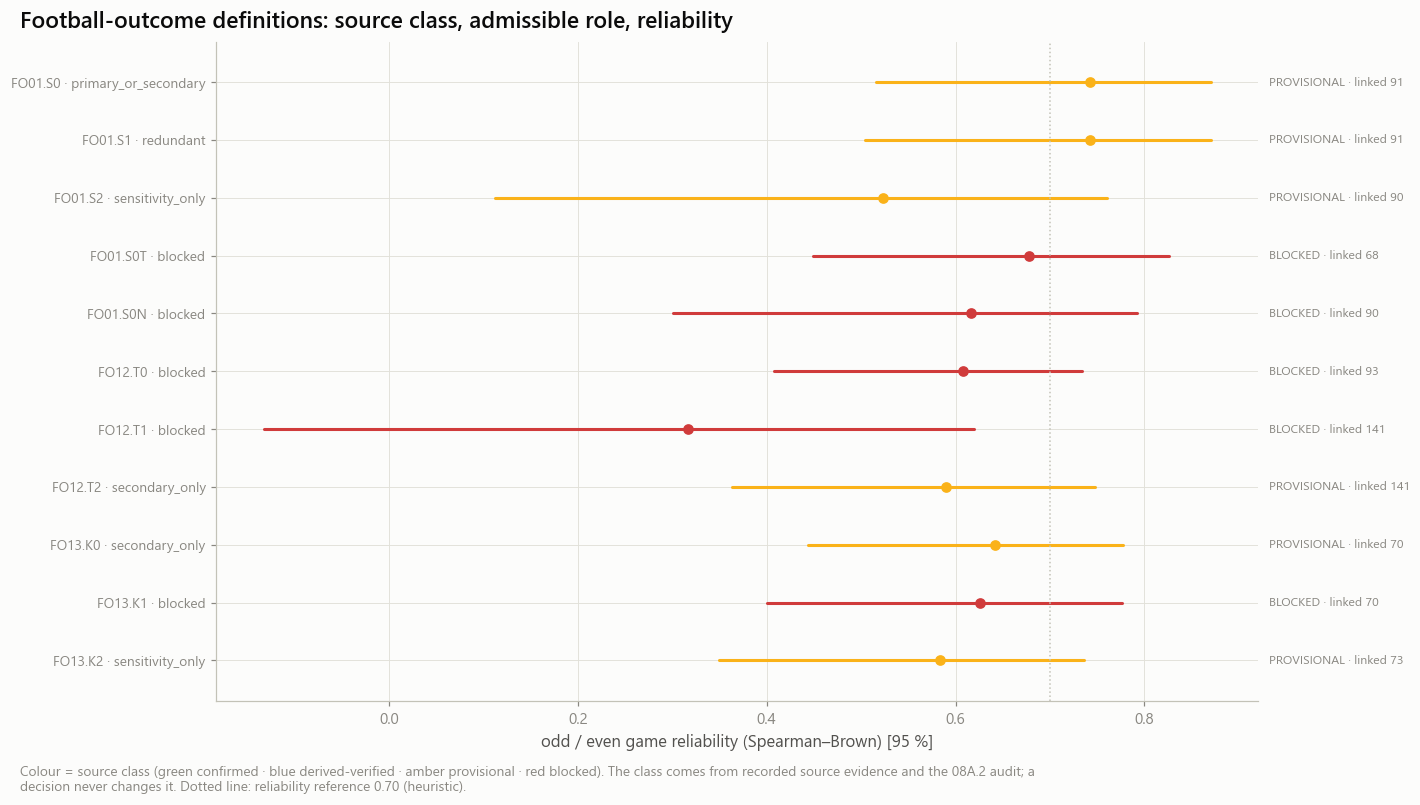

In [9]:
screen = ov.screen_table(denoms, SEMANTIC, reliability, dependence, funnel, vc)
definitions = save(fr.definitions_table(screen, SEMANTIC, lineage, equivalences), fr.DEFINITIONS)
PROPOSAL = fr.propose(definitions)
with pl.Config(fmt_str_lengths=170, tbl_rows=-1, tbl_width_chars=260):
    display(definitions.select('definition_id', 'source_class', 'role_allowed', 'redundant_with', 'n_linked_all_models', 'rel_sb', 'rel_lo', 'exposure_rho', 'class_basis'))
    display(definitions.select('definition_id', 'interpretation_label'))
display(Markdown(f'**Rule-based proposal (a recommendation, never a decision):** `{PROPOSAL["decision"]}` · primary `{PROPOSAL["primary"]}` · secondary {PROPOSAL["secondary"]} — '
                 f'{PROPOSAL["basis"]}'))
store.show(ff.fig_definition_classes(definitions), 'AM08B0_01_definition_source_classes', {'definitions': definitions}, publication=True,
           source='football_outcome_definition_classes', n='linked athletes per definition')

## 7 · Manual target selection — **your decision**

| `DECISION` | Scientific meaning | Effect |
|---|---|---|
| `'FREEZE'` | The definitions are **locked** for Milestone 08B. If every target is `CONFIRMED` / `DERIVED_VERIFIED`: `frozen_confirmed`. If any target is `PROVISIONAL`: `frozen_exploratory` — needs `ACKNOWLEDGE_PROVISIONAL = True`; every result is labelled exploratory. | 08B.1–08B.3 run |
| `'PROVISIONAL'` | The definitions are **recorded for review and may still change** (in a new version). With the acknowledgement: `provisional_exploratory` — exploratory analyses allowed, never a confirmed predictive claim. Without it: `provisional_review`. | with acknowledgement: 08B.1–08B.3 run as exploratory · without: blocked |
| `'STOP'` | No football outcome is defensible. | football transfer blocked; 08B.4–08B.6 continue |
| `None` | Pending. | nothing written; football transfer blocked |

`PRIMARY` / `SECONDARY` are definition IDs (one per outcome, at most two secondaries). Blocked, redundant and sensitivity-only definitions are refused; T2 and K0 can only be secondary.

`HYPOTHESES` fixes the comparisons of 08B.2 **now**, before any NFL outcome is related to a Combine value: one primary (`M2` versus `M1`: one pre-selected interpretable tracking family beyond official testing) and the declared secondaries. Change it only for a reason you write in `RATIONALE`.

The registry is written once. Rerunning with the same decision reproduces it; any change needs a new `REGISTRY_VERSION` and leaves the old file in place.

In [12]:
# ============================================================
# MILESTONE 08B.0 — FOOTBALL OUTCOME RESEARCH DECISION
# ============================================================

DECISION = "FREEZE"

# Primary football outcome: WR/TE separation
PRIMARY = "FO01.S0"

# Secondary exploratory football outcomes
SECONDARY = [
    "FO12.T2",  # Tackle/assist credits per eligible defensive snap
    "FO13.K0",  # Recorded sack outcome; opportunity limitations
]

# Explicit acknowledgment of inferred source definitions
ACKNOWLEDGE_PROVISIONAL = True

RATIONALE = (
    "We freeze FO01.S0 as the primary EXPLORATORY football outcome "
    "because it has the strongest combination of football relevance, "
    "observed athlete coverage and preliminary across-game reliability "
    "among the candidates evaluated without consulting Combine-to-NFL "
    "predictive correlations. FO01.S0 uses the recorded separation_at_pass_forward "
    "field, whose precise provider semantics remain plausible but unconfirmed. "
    "FO01.S1 is operationally redundant with S0 in the observed population, "
    "while FO01.S2 shows lower preliminary reliability and is retained "
    "for sensitivity analysis only. FO12.T2 is retained as a secondary "
    "tackle-or-assist credit rate per eligible defensive snap, not as tackling "
    "success probability. FO13.K0 is retained as a secondary recorded sack "
    "outcome, not as a pass-rush win rate or opportunity-adjusted sack rate. "
    "The source definitions and opportunity denominators remain subject "
    "to their documented limitations. All subsequent football-transfer "
    "analyses are EXPLORATORY, and these outcomes must not be described "
    "as independently validated measures of player skill. This selection "
    "was made from semantic plausibility, coverage, reliability and physical "
    "interpretability rather than favorable Combine prediction results."
)

HYPOTHESES = fr.HYPOTHESES_DEFAULT

21:49:02 | INFO    | nflbdb.research.advanced_movement.football_registry | [football_registry] football_outcome_registry_v1.json written: FREEZE ['FO01.S0', 'FO12.T2', 'FO13.K0']
21:49:02 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:08B0] football_gate_a_semantics: 5 rows → warehouse/gold/advanced_movement/football_v1/football_gate_a_semantics.parquet


registry: recorded now (frozen_exploratory)


criterion,passed,detail
str,bool,str
"""lineage_recorded_for_every_field""",true,"""12 fields; 0 with recorded source evidence"""
"""unresolved_semantics_stay_visible""",true,"""definitions by class: BLOCKED 5, PROVISIONAL 6"""
"""decision_recorded""",true,"""FREEZE → frozen_exploratory"""
"""no_source_class_upgraded""",true,"""FO01.S0 PROVISIONAL, FO12.T2 PROVISIONAL, FO13.K0 PROVISIONAL"""
"""football_transfer_allowed""",true,"""EXPLORATORY — source semantics inferred; definitions locked — strongest claim: exploratory association only — never a confirmed predictive claim"""


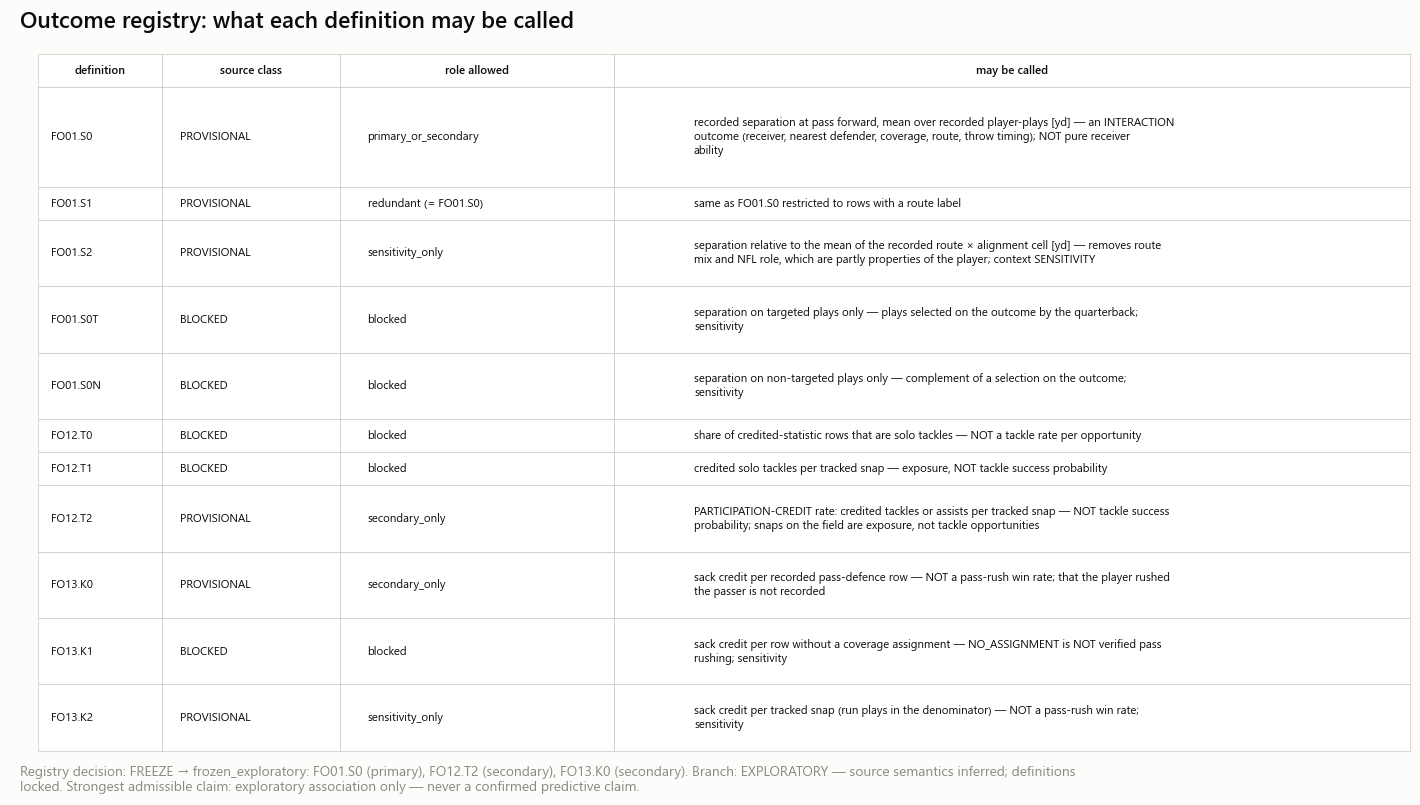

### 08B.0 — outcome resolution and registry

Branch: **EXPLORATORY — source semantics inferred; definitions locked**. Strongest admissible claim: exploratory association only — never a confirmed predictive claim.

| Definition | Source class | Role allowed | Linked | Reliability [95 %] | May be called |
|---|---|---|---|---|---|
| `FO01.S0` | PROVISIONAL | primary_or_secondary | 91 | 0.74 [0.52, 0.87] | recorded separation at pass forward, mean over recorded player-plays [yd] — an INTERACTION outcome (receiver, nearest defender, coverage, route, throw timing); NOT pure receiver ability |
| `FO01.S1` | PROVISIONAL | redundant (= `FO01.S0`) | 91 | 0.74 [0.50, 0.87] | same as FO01.S0 restricted to rows with a route label |
| `FO01.S2` | PROVISIONAL | sensitivity_only | 90 | 0.52 [0.11, 0.76] | separation relative to the mean of the recorded route × alignment cell [yd] — removes route mix and NFL role, which are partly properties of the player; context SENSITIVITY |
| `FO01.S0T` | BLOCKED | blocked | 68 | 0.68 [0.45, 0.83] | separation on targeted plays only — plays selected on the outcome by the quarterback; sensitivity |
| `FO01.S0N` | BLOCKED | blocked | 90 | 0.62 [0.30, 0.79] | separation on non-targeted plays only — complement of a selection on the outcome; sensitivity |
| `FO12.T0` | BLOCKED | blocked | 93 | 0.61 [0.41, 0.73] | share of credited-statistic rows that are solo tackles — NOT a tackle rate per opportunity |
| `FO12.T1` | BLOCKED | blocked | 141 | 0.32 [-0.13, 0.62] | credited solo tackles per tracked snap — exposure, NOT tackle success probability |
| `FO12.T2` | PROVISIONAL | secondary_only | 141 | 0.59 [0.36, 0.75] | PARTICIPATION-CREDIT rate: credited tackles or assists per tracked snap — NOT tackle success probability; snaps on the field are exposure, not tackle opportunities |
| `FO13.K0` | PROVISIONAL | secondary_only | 70 | 0.64 [0.44, 0.78] | sack credit per recorded pass-defence row — NOT a pass-rush win rate; that the player rushed the passer is not recorded |
| `FO13.K1` | BLOCKED | blocked | 70 | 0.63 [0.40, 0.78] | sack credit per row without a coverage assignment — NO_ASSIGNMENT is NOT verified pass rushing; sensitivity |
| `FO13.K2` | PROVISIONAL | sensitivity_only | 73 | 0.58 [0.35, 0.74] | sack credit per tracked snap (run plays in the denominator) — NOT a pass-rush win rate; sensitivity |

- FO01.S1 is operationally identical to FO01.S0 on the observed data: retain FO01.S0, classify FO01.S1 as redundant (common athletes 116, same observation counts 116).

Decision **FREEZE** → `frozen_exploratory` (registry `v1`, hash `475f557b0f0a0685`): `FO01.S0` (primary, PROVISIONAL), `FO12.T2` (secondary, PROVISIONAL), `FO13.K0` (secondary, PROVISIONAL).
Rationale: We freeze FO01.S0 as the primary EXPLORATORY football outcome because it has the strongest combination of football relevance, observed athlete coverage and preliminary across-game reliability among the candidates evaluated without consulting Combine-to-NFL predictive correlations. FO01.S0 uses the recorded separation_at_pass_forward field, whose precise provider semantics remain plausible but unconfirmed. FO01.S1 is operationally redundant with S0 in the observed population, while FO01.S2 shows lower preliminary reliability and is retained for sensitivity analysis only. FO12.T2 is retained as a secondary tackle-or-assist credit rate per eligible defensive snap, not as tackling success probability. FO13.K0 is retained as a secondary recorded sack outcome, not as a pass-rush win rate or opportunity-adjusted sack rate. The source definitions and opportunity denominators remain subject to their documented limitations. All subsequent football-transfer analyses are EXPLORATORY, and these outcomes must not be described as independently validated measures of player skill. This selection was made from semantic plausibility, coverage, reliability and physical interpretability rather than favorable Combine prediction results.

A decision never raises a source class. A PROVISIONAL class becomes CONFIRMED only when the analyst records a named, authoritative source and the quoted definition, in a NEW registry version.

In [13]:
REGISTRY, message = fr.record_decision(store, DECISION, PRIMARY, SECONDARY, RATIONALE, ACKNOWLEDGE_PROVISIONAL, definitions=definitions, screen=screen,
                                       athletes=athletes, semantic=SEMANTIC, lineage=lineage, cfg=vc, provenance=PROV, hypotheses=HYPOTHESES,
                                       version=REGISTRY_VERSION)
BRANCH = fr.branch(REGISTRY)
gate_a = save(fr.gate_a(REGISTRY, definitions, lineage), fr.GATE_A)
print('registry:', message)
with pl.Config(fmt_str_lengths=200, tbl_rows=-1):
    display(gate_a)
store.show(ff.fig_decision(definitions, BRANCH, REGISTRY), 'AM08B0_02_registry_decision', {'definitions': definitions},
           source='football_outcome_registry', n='definitions')
text = fr.conclusions_markdown(definitions, equivalences, REGISTRY)
display(Markdown(text))
if controls.save_tables:
    store.tables_dir.mkdir(parents=True, exist_ok=True)
    (store.tables_dir / 'football_outcome_resolution_conclusions.md').write_text(text, encoding='utf-8')
    store.write_json('football_outcome_resolution_manifest', {
        'experiment_version': EXPERIMENT_VERSION, 'finished_at': utc_now(), 'registry_version': REGISTRY_VERSION, 'registry_message': message,
        'registry_hash': (REGISTRY or {}).get('version_hash'), 'decision': DECISION, 'branch': BRANCH, 'proposal': PROPOSAL,
        'gate_a': 'PASS' if bool(gate_a['passed'].all()) else ('PENDING' if REGISTRY is None else 'BLOCKED'), 'provenance': PROV,
        'source_classes': dict(zip(definitions['definition_id'], definitions['source_class']))})

## 8 · Reading

- **Gate A — outcome semantics.** The target can be interpreted legitimately only within its source class. `football_transfer_allowed` says which branch the later notebooks take: *frozen* (confirmed definitions), *exploratory* (inferred semantics, explicitly acknowledged) or *blocked*.
- A `PROVISIONAL` class is not a defect to hide: it caps every later claim at **exploratory association**.
- If the branch is blocked, run 08B.4 → 08B.5 → 08B.6: the descriptive information analysis, the scorecard and the evidence package do not need a football outcome.

**Send back:** the checks table, the definitions table, the equivalence line, `registry:` message, Gate A, and figure `AM08B0_01`.

**Next:** `08b1_football_outcome_reliability.ipynb` (frozen or exploratory branch) — or `08b4_incremental_movement_information.ipynb` (blocked branch).